In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import visualastro as va

### set the plot style and color cycle
`'full'` adds major and minor ticks to all splines while `cm` sets the font to computer-modern.

In [2]:
plt.style.use(['full', 'cm']) 

### Generate synthetic spectra


In [3]:
rng = np.random.default_rng(42)

wavelength = np.linspace(4000, 7000, 1500)

flux = (wavelength / 5500) ** -1.5

# emission line (H-alpha) and absorption line (H-beta)
flux += 2.0 * np.exp(-0.5 * ((wavelength - 6562.8) / 8) ** 2)
flux -= 0.4 * np.exp(-0.5 * ((wavelength - 4861) / 6) ** 2)

flux += rng.normal(0, 0.03, wavelength.size)

wavelength *= u.AA

### Adding Spectra line markers

to add one line, use `va.spectral_line_marker`. For multiple lines, use `va.spectral_lines`.

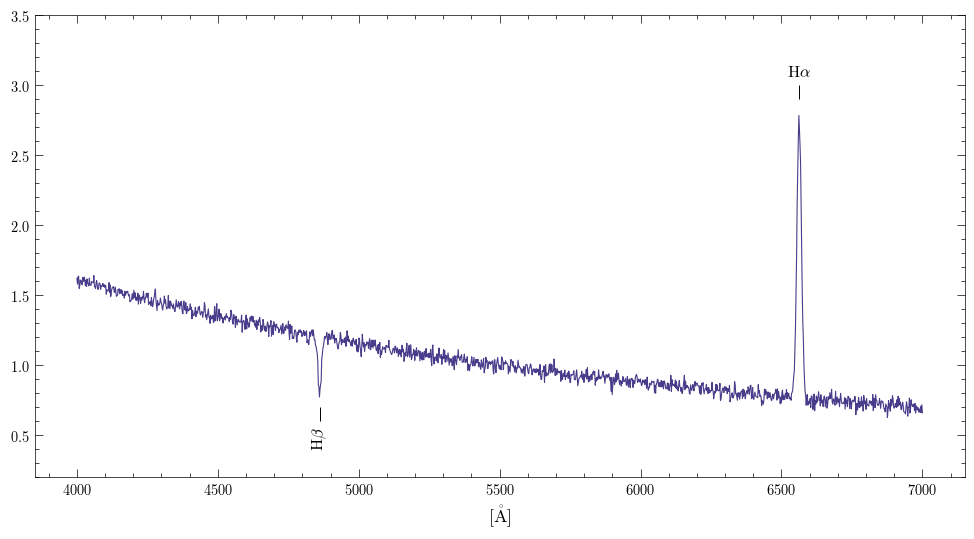

In [4]:
va.plot(wavelength, flux, color='darkslateblue', figsize=(12,6), ylim=(0.2, 3.5))

va.spectral_line_marker(4861, style='marker', label=r'H$\beta$', y=.7, h=0.1, direction='up', rotation=90)
va.spectral_line_marker(6562.8, style='marker', label=r'H$\alpha$', y=2.9, h=0.1)

plt.show()

`spectral_lines` will plot a vline or marker for each wavelength. Identical labels are groupped together and are asigned identical colors.

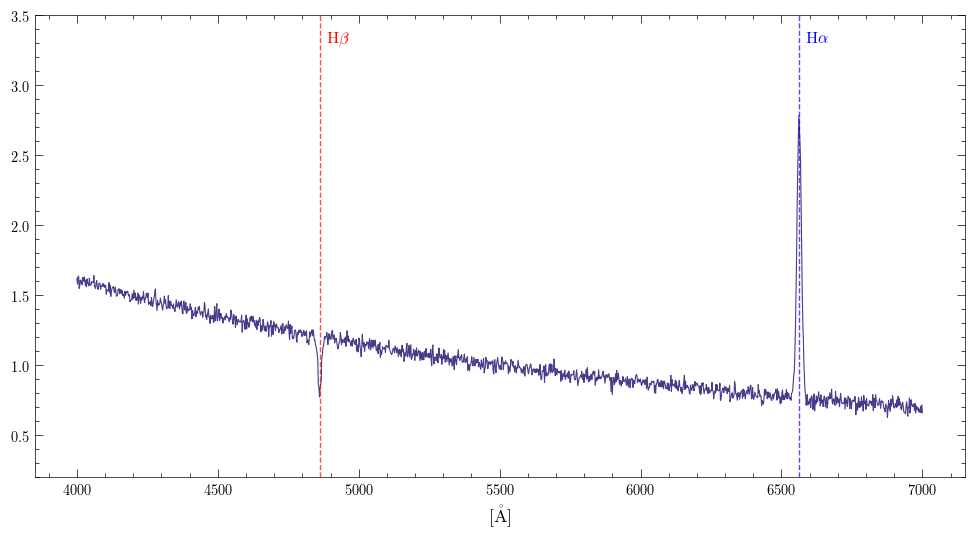

In [5]:
ws = [4861, 6562.8]
labels = [r'H$\beta$', r'H$\alpha$']
va.plot(wavelength, flux, color='darkslateblue', figsize=(12,6), ylim=(0.2, 3.5))
va.spectral_lines(wavelengths=ws, labels=labels, style='vline', color=['r', 'b'], lw=1, label_offset_points=[13, -10])
plt.show()

### Inset axes

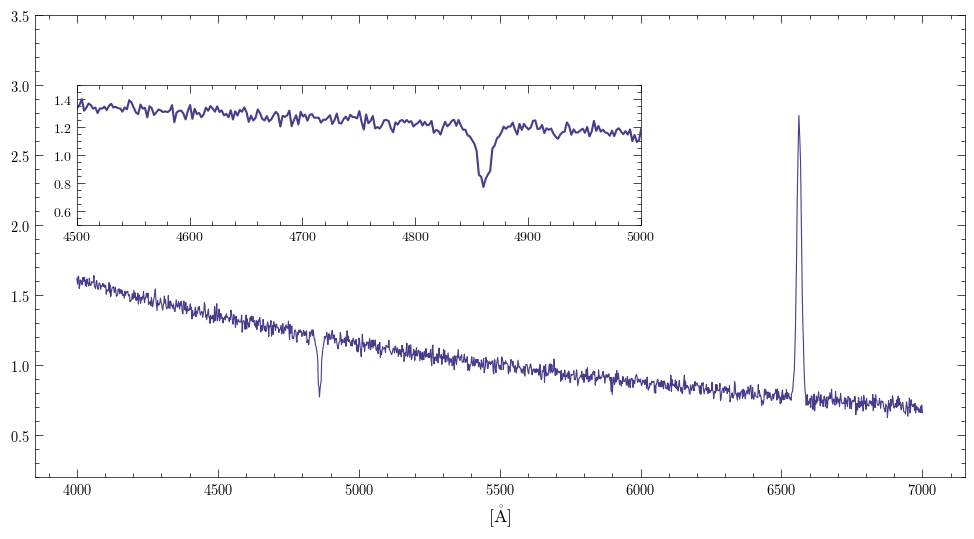

In [6]:
va.plot(wavelength, flux, color='darkslateblue', figsize=(12,6), ylim=(0.2, 3.5))

inset = va.inset_axes(
    bounds=[4000, 2, 2000, 1], transform='data', xlim=(4500, 5000), ylim=(0.5, 1.5)
)
inset.plot(wavelength, flux, color='darkslateblue')

plt.show()

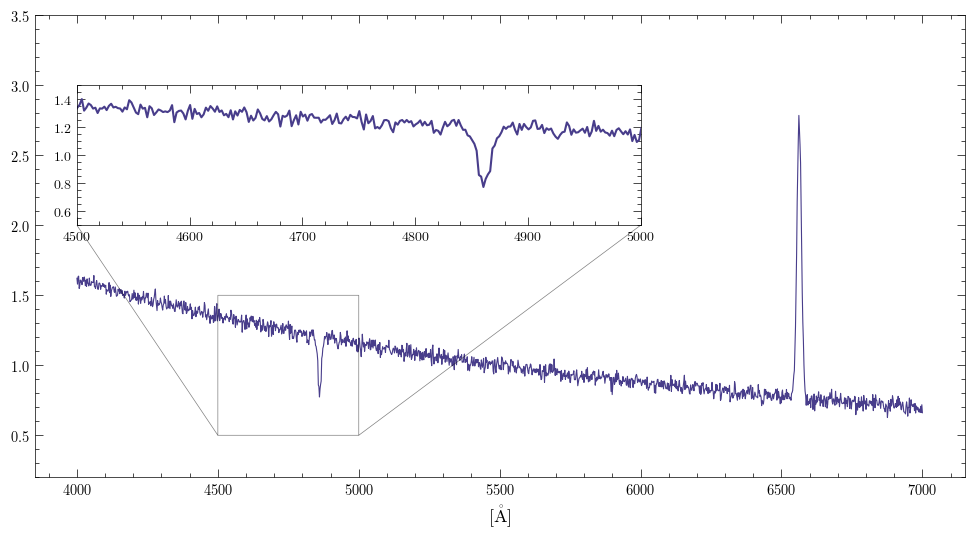

In [7]:
va.plot(wavelength, flux, color='darkslateblue', figsize=(12,6), ylim=(0.2, 3.5))

inset = va.inset_axes(
    bounds=[4000, 2, 2000, 1], transform='data', xlim=(4500, 5000), ylim=(0.5, 1.5), indicate_zoom=True
)
inset.plot(wavelength, flux, color='darkslateblue')

plt.show()

#### Changing the connectors
use `connectors=[bool, bool, bool, bool]`

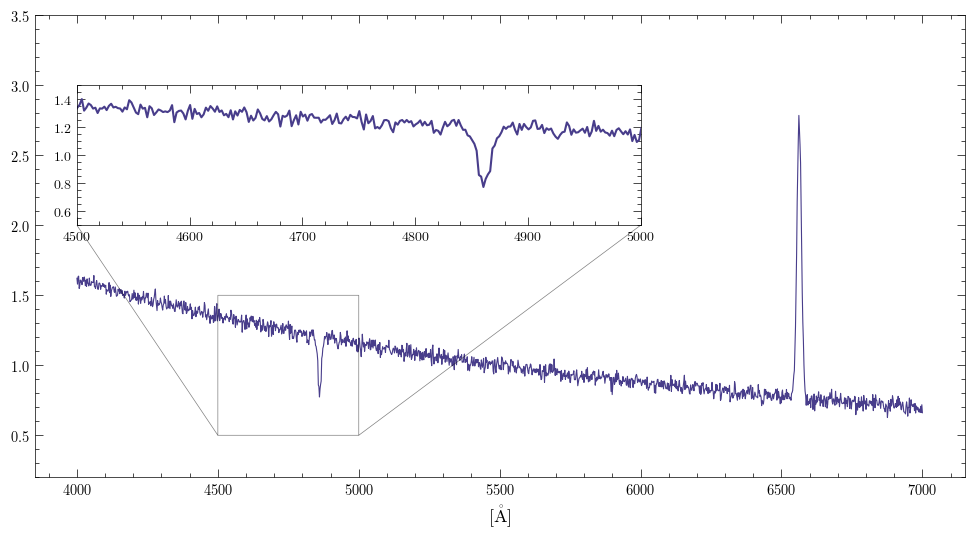

In [8]:
va.plot(wavelength, flux, color='darkslateblue', figsize=(12,6), ylim=(0.2, 3.5))

inset = va.inset_axes(
    bounds=[4000, 2, 2000, 1], transform='data', xlim=(4500, 5000), 
    ylim=(0.5, 1.5), indicate_zoom=True, 
    connectors=[True, False, True, False]
)
inset.plot(wavelength, flux, color='darkslateblue')

plt.show()

### More styles

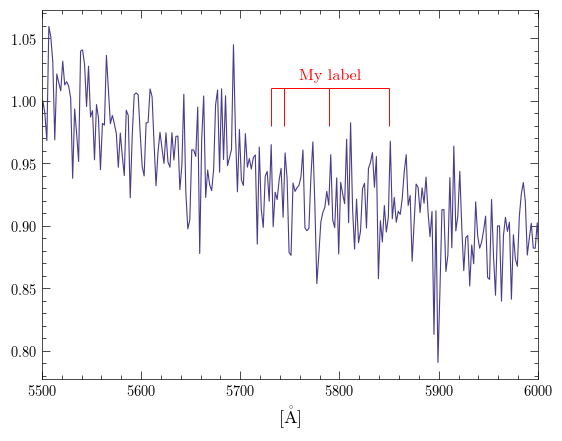

In [9]:
fig, ax = plt.subplots()
va.plot(wavelength, flux, xlim=(5500, 6000), color='darkslateblue')
va.spectral_line_marker(5731, 5744, 5789, 5850, style='marker', y=.98, h=0.03, label='My label', color='r')
plt.show()

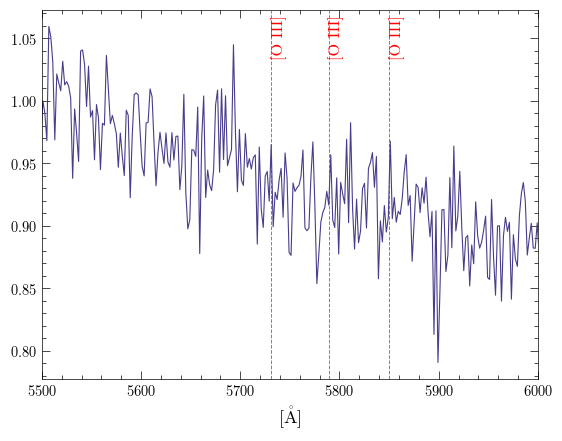

In [10]:
fig, ax = plt.subplots()
va.plot(wavelength, flux, xlim=(5500, 6000), color='darkslateblue')
va.spectral_line_marker(5731, 5789, 5850, style='vline', label='[O III]', color='r', rotation=90, label_anchor='left')
plt.show()